# OP-FL v2 — 08. Analyse exploratoire : la petite taille des sites explique-t-elle la baisse de la pente b ?

**Statut : exploratoire, après l'ouverture du test verrouillé.** Rien ici ne modifie les résultats confirmatoires du notebook 07.

**Constat.** La pente de calibration des sites vaut b ≈ 0,92 sur le développement (médiane des partitions du 06d) contre b = 0,54 sur le test verrouillé (07). OP-Cal y prédit correctement le sens des écarts, mais avec une échelle environ deux fois trop grande.

**Hypothèse testée.** Les hôpitaux verrouillés sont petits. Leurs descripteurs sont donc calculés sur peu de séjours (split train), et le groupe « modèle » (moyenne et écart-type du score) sur peu de patients d'évaluation. Ces descripteurs bruités dispersent trop â_h : c'est l'atténuation classique due aux erreurs de mesure sur les covariables. Le bruit des cibles a_h, lui, ne biaise pas b.

**Règles.**
* Seuls les hôpitaux de développement sont analysés. Des hôpitaux verrouillés, on lit uniquement :
  * les effectifs du manifest (`n_train`, `n_val`, `n_test`), pour fixer la taille des sous-échantillons ;
  * la pente b déjà publiée par le 07 (`resultats_confirmatoires.json`), comme valeur à expliquer ;
  * les â_h gelés en phase A du 07 (sans label), pour comparer leur dispersion.
* **Aucun label verrouillé n'est lu.**
* Les critères ci-dessous sont fixés avant l'analyse et enregistrés dans `plan_08.json` (étape 0). Si ce fichier existe déjà avec un contenu différent, le notebook s'arrête. Commite ce notebook **avant** de l'exécuter.
* La correction de l'étape 5 n'est évaluée que si l'hypothèse est soutenue. **Elle ne sera jamais évaluée sur les 96 hôpitaux verrouillés** : ce jeu a servi.

**Plan.** On sous-échantillonne chaque hôpital de développement. Il reçoit les effectifs d'un hôpital verrouillé tiré au hasard : séjours train pour les descripteurs, patients d'évaluation pour le groupe « modèle » et les cibles. On répète 50 fois, sur les plis du protocole et sur 10 partitions aléatoires (les 10 premières du 06d). Le méta-modèle (`SiteEB`, 44 descripteurs gelés) est appris à taille complète sur les autres plis, comme au 07.

| Scénario | Sous-échantillonné | Ce qu'il isole |
|---|---|---|
| `complet` | rien | référence du développement |
| `cibles ×1` | cibles a_h (patients d'évaluation) | bruit des cibles : ne doit pas abaisser b |
| `groupe_modele ×1` | moyenne et écart-type du score | bruit du groupe « modèle » |
| `descripteurs ×1` | séjours train (descripteurs patients) | bruit des autres descripteurs |
| `tout ×1` | tout, à la taille des verrouillés | situation du test verrouillé |
| `tout ×0,5`, `tout ×2` | tout, à la moitié ou au double | relation dose-effet |

**Critères de l'hypothèse (H-taille)**, avec b_complet = médiane de b sur les partitions à taille complète, b_tout = médiane de b sous `tout ×1` et b_07 = 0,540 :
* **S1** : la baisse simulée b_complet − b_tout atteint au moins la moitié de la baisse observée b_complet − b_07.
* **S2** : b_07 se situe entre les 5e et 95e centiles de b sous `tout ×1`.
* **S3** (mécanisme) : la baisse sous `cibles ×1` est au plus un tiers de la baisse sous `tout ×1`.
* H-taille est **soutenue** si S1 et S2 sont vrais. S3 dit si le mécanisme est l'erreur de mesure des descripteurs.

**Correction candidate (étape 5, seulement si H-taille est soutenue).** Elle est fixée à l'avance et n'a aucun paramètre à régler :
* â_corr = μ + λ_h (â_h − μ), avec λ_h = (σ²_a + q̄) / (σ²_a + q_h) ;
* q_h = w' C_h w est la variance de â_h due à l'échantillonnage des descripteurs du site. Elle se calcule sans label, par la méthode delta sur les séjours de l'hôpital ;
* q̄ est le bruit moyen des hôpitaux d'entraînement, et σ²_a la variance de â entre eux moins q̄.

Le méta-modèle est déjà calibré pour des descripteurs mesurés avec le bruit du développement. On a donc λ_h = 1 pour un hôpital de même taille, et λ_h < 1 pour un hôpital plus petit (calibration de régression).

Elle est retenue comme **candidate**, à valider sur une autre source, si les quatre critères suivants sont vrais sous `tout ×1` :
* **K1** : la médiane de b corrigé est comprise entre 0,8 et 1,2.
* **K2** : le gain de log-vraisemblance contre E0 est plus grand avec correction que sans dans au moins 75 % des réplications, et sa médiane avec correction est > 0.
* **K3** (aucun dommage à taille complète) : sous `complet`, la variation médiane de \|CITL\| est ≤ 0,005, et celle de b est ≤ 0,10 en valeur absolue.
* **K4** (modèle de bruit correct) : la médiane de (â − â complet)² / (q − q complet) est comprise entre 0,7 et 1,3.

## Étape 0 — Configuration, intégrité et plan d'analyse (enregistré avant tout calcul)

In [1]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION, INTÉGRITÉ, PLAN D'ANALYSE
# ============================================================
import sys, json, re, time, hashlib, importlib, warnings
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES02 = PROJECT_DIR / "results" / "02_baselines"
RES04 = PROJECT_DIR / "results" / "04_observation_label"
RES06B = PROJECT_DIR / "results" / "06b_faisabilite_opcal"
RES06C = PROJECT_DIR / "results" / "06c_robustesse_opcal"
RES06D = PROJECT_DIR / "results" / "06d_amendement_puissance"
RES07 = PROJECT_DIR / "results" / "07_confirmation"
RES_DIR = PROJECT_DIR / "results" / "08_taille_sites"
FIG_DIR = RES_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
FOLDS = sorted(int(k) for k in protocol["folds"])
DEV = sorted(int(h) for k in protocol["folds"] for h in protocol["folds"][k])
LOCKED = set(int(h) for h in protocol["locked_test_hospitals"])

# intégrité : le 08 ne touche ni à la spécification, ni à l'amendement, ni aux modules confirmatoires
SPEC_PATH, AMEND_PATH = RES06C / "specification_gelee.json", RES06D / "amendement_1.json"
SPEC, AMEND = json.loads(SPEC_PATH.read_text(encoding="utf-8")), json.loads(AMEND_PATH.read_text(encoding="utf-8"))
OSF = (RES06D / "depot_osf.md").read_text(encoding="utf-8")
INTEGRITE = {"spécification et amendement inchangés (empreintes du texte de dépôt)": sha256(SPEC_PATH) in OSF and sha256(AMEND_PATH) in OSF,
             **{f"module {f} inchangé": sha256(SRC_DIR / f) == h for f, h in AMEND["code_sha256"].items()}}
for k, v in INTEGRITE.items():
    print(("OK     " if v else "ÉCHEC  ") + k)
assert all(INTEGRITE.values()), "Fichiers confirmatoires modifiés : vérifier avant toute analyse exploratoire."

RES_CONF = json.loads((RES07 / "resultats_confirmatoires.json").read_text(encoding="utf-8"))
B_07, B_07_IC = float(RES_CONF["C1"]["b"]), (float(RES_CONF["C1"]["b_IC_bas"]), float(RES_CONF["C1"]["b_IC_haut"]))
FROZEN = SPEC["meta_modele"]["descripteurs"]
print(f"\nPente du test verrouillé (07, à expliquer) : b = {B_07:.3f} [{B_07_IC[0]:.3f} ; {B_07_IC[1]:.3f}] ; {len(FROZEN)} descripteurs gelés")

# plan d'analyse : fixé ici, enregistré avant tout calcul
SEED, N_DRAW, N_PART = 2026, 50, 10
CONFIGS = [("complet", None), ("cibles", 1.0), ("groupe_modele", 1.0), ("descripteurs", 1.0), ("tout", 1.0), ("tout", 0.5), ("tout", 2.0)]
PLAN = {
    "document": "Plan d'analyse exploratoire du notebook 08 (taille des sites)",
    "statut": "exploratoire, après l'ouverture du test verrouillé ; ne modifie pas les résultats confirmatoires",
    "protocol_hash": protocol["hash"], "specification_sha256": sha256(SPEC_PATH), "amendement_sha256": sha256(AMEND_PATH),
    "b_test_verrouille": B_07,
    "acces_verrouille": ["manifest : hospitalid, role, n_train, n_val, n_test", "resultats_confirmatoires.json : b publié",
                         "engagement_predictions_hopitaux_x_only.parquet : â_h gelés, sans label"],
    "graine": SEED, "tirages": N_DRAW, "partitions_aleatoires": N_PART, "configurations": [[s, e] for s, e in CONFIGS],
    "hypothese": {"S1": "b_complet − b_tout ≥ 0,5 × (b_complet − b_07), avec b_complet − b_07 > 0",
                  "S2": "P5 ≤ b_07 ≤ P95 de b sous « tout ×1 »",
                  "S3": "b_complet − b_cibles ≤ (b_complet − b_tout) / 3",
                  "verdict": "soutenue si S1 et S2 ; S3 renseigne le mécanisme"},
    "correction": {"definition": "â_corr = μ + λ_h (â_h − μ), λ_h = (σ²_a + q̄) / (σ²_a + q_h), q_h = w' C_h w (méthode delta, sans label), q̄ = bruit moyen du développement",
                   "condition": "évaluée seulement si l'hypothèse est soutenue ; jamais sur les 96 hôpitaux verrouillés",
                   "K1": "médiane de b corrigé dans [0,8 ; 1,2] sous « tout ×1 »",
                   "K2": "gain vs E0 corrigé > non corrigé dans ≥ 75 % des réplications et médiane corrigée > 0, sous « tout ×1 »",
                   "K3": "sous « complet » : |médiane Δ|CITL|| ≤ 0,005 et |médiane Δb| ≤ 0,10",
                   "K4": "médiane du rapport de bruit dans [0,7 ; 1,3] sous « tout ×1 »",
                   "verdict": "candidate (validation externe nécessaire) si K1 à K4 ; sinon non retenue"},
    "seuils": {"S1_part": 0.5, "S3_part": 1 / 3, "K1": [0.8, 1.2], "K2_part": 0.75, "K3_abs": 0.005, "K3_b": 0.10, "K4": [0.7, 1.3]},
}
PLAN_PATH = RES_DIR / "plan_08.json"
if PLAN_PATH.exists():
    old = json.loads(PLAN_PATH.read_text(encoding="utf-8"))
    same = {k: v for k, v in old.items() if k != "date"} == PLAN
    assert same, "plan_08.json existe déjà avec un autre contenu : le plan ne doit pas changer après une exécution."
    PLAN = old
else:
    PLAN["date"] = datetime.now().isoformat(timespec="seconds")
    PLAN_PATH.write_text(json.dumps(PLAN, indent=2, ensure_ascii=False), encoding="utf-8")
PLAN_SHA = sha256(PLAN_PATH)
TH = PLAN["seuils"]
print(f"Plan d'analyse : {PLAN_PATH.name} du {PLAN['date']} (SHA-256 {PLAN_SHA[:16]}…)")

OK     spécification et amendement inchangés (empreintes du texte de dépôt)
OK     module opcal_feas.py inchangé
OK     module opcal_robust.py inchangé
OK     module opcal_amend.py inchangé

Pente du test verrouillé (07, à expliquer) : b = 0.540 [0.252 ; 0.829] ; 44 descripteurs gelés
Plan d'analyse : plan_08.json du 2026-10-30T14:29:19 (SHA-256 870db4740ae0a7d2…)


## Étape 1 — Module `src/opcal_size.py`

Le module contient :
* le calcul des descripteurs gelés sur n'importe quel sous-ensemble de séjours, avec leur covariance d'échantillonnage (sans label) ;
* les méta-modèles par pli et la correction de fiabilité ;
* les réplications et les critères du protocole.

In [2]:
%%writefile ../src/opcal_size.py
"""
opcal_size — analyse exploratoire du notebook 08 : la petite taille des hôpitaux verrouillés explique-t-elle la baisse
de la pente b entre le développement et le test verrouillé ?

Généré par notebooks/08_taille_sites.ipynb (étape 1) : modifier le notebook, pas ce fichier.
Hôpitaux de développement uniquement. Des hôpitaux verrouillés, seuls les effectifs du manifest (n_train, n_val + n_test)
sont utilisés, pour fixer la taille des sous-échantillons.

- DevArrays : recalcule les descripteurs gelés sur n'importe quel sous-ensemble de séjours, avec les règles de
  opcal_feas.site_descriptors et du notebook 01, et donne leur covariance d'échantillonnage (fonctions d'influence,
  méthode delta). Ce calcul n'utilise aucun label : un hôpital pourrait le faire localement.
- fit_folds / predict : SiteEB par pli, appris à taille complète comme opcal_feas.crossfit_prior ; correction de
  fiabilité de â (étape 5, fixée avant l'analyse, sans paramètre à régler).
- run : sous-échantillonnage répété, puis critères du protocole (c1_analysis, gain de log-vraisemblance, |CITL|).
"""
import json
from pathlib import Path

import numpy as np
import pandas as pd

import opcal_feas as oc
import opcal_amend as am

AVAIL_MIN_COVERAGE = 0.05          # notebook 01 : variable disponible si >= 5 % des séjours train l'observent
OBS_SUBSET = ("test_rate_lactate", "test_rate_creatinine", "intensity_lactate", "intensity_creatinine")
MODEL = ("mean_lp", "sd_lp")
# scénario -> (split train sous-échantillonné, groupe « modèle » sur l'évaluation sous-échantillonnée,
#              cibles a_h et gains sur l'évaluation sous-échantillonnée)
SCENARIOS = {"complet": (False, False, False), "descripteurs": (True, False, False),
             "groupe_modele": (False, True, False), "cibles": (False, False, True), "tout": (True, True, True)}


def _subset_mean(z, P, k, sel, x):
    """Moyenne de x sur les séjours `sel` (valeurs finies) et sa fonction d'influence (estimateur de ratio)."""
    s = sel & np.isfinite(x)
    if s.any():
        zk = float(x[s].mean())
        z[k] = zk
        P[:, k] = np.where(s, x - zk, 0.0) / s.mean()


class DevArrays:
    """Tableaux par hôpital de développement.
    st : stay_labels (index stay_id, développement) ; cohort : cohort_final (développement) avec patientunitstayid,
    age_num, gender, apacheadmissiondx, unittype, unitadmitsource ; transfer : stay_id, hospitalid, lp, y (patients
    d'évaluation, modèle du pli) ; struct : descripteurs de structure (index hospitalid) ; cols : descripteurs gelés."""

    def __init__(self, data_dir, st, cohort, transfer, struct, cols):
        data_dir = Path(data_dir)
        feats = json.loads((data_dir / "features.json").read_text(encoding="utf-8"))["features"]
        fidx = {f: i for i, f in enumerate(feats)}
        self.cols = list(cols)
        pos = self.pos = {c: i for i, c in enumerate(self.cols)}
        groups = [(n, [fidx[v] for v in vs if v in fidx]) for n, vs in oc.OBS_COV.items()]
        groups.append(("mean_coverage", list(range(len(feats)))))
        self.groups = [(pos[n], ii) for n, ii in groups if n in pos and ii]
        self.share_cols = [c for c in self.cols if c == "female_share" or c.startswith(("unit_", "src_", "dx_"))]
        self.share_idx = np.array([pos[c] for c in self.share_cols], int)
        known = set(oc.OBS_COV) | {"n_unavailable", "mean_coverage", "age_mean", *OBS_SUBSET, *MODEL, *self.share_cols}
        self.struct_cols = [c for c in self.cols if c not in known]
        unknown = [c for c in self.struct_cols if not c.startswith(("beds_cat", "teaching", "region_")) or c not in struct.columns]
        assert not unknown, f"Descripteurs gelés de nature inconnue (ni patient ni structure) : {unknown}"
        self.struct_idx = np.array([pos[c] for c in self.struct_cols], int)
        self.model_idx = np.array([pos[c] for c in MODEL if c in pos], int)
        coh = cohort.set_index("patientunitstayid")
        self.H, self._full = {}, {}
        for h, ev in transfer.groupby("hospitalid"):
            h = int(h)
            z = np.load(data_dir / "clients" / f"hospital_{h}.npz")
            tr = np.asarray(z["split"]) == 0
            ids = np.asarray(z["stay_id"])[tr]
            obs = np.asarray(z["M"])[tr].any(axis=1)                          # (n_train, F) : observé en 24 h
            c = coh.reindex(ids)
            unit = "unit_" + c["unittype"].astype(str).str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
            src = c["unitadmitsource"].map(oc.SRC_GROUPS).fillna("src_other")
            dx = c["apacheadmissiondx"].fillna("").astype(str).str.lower()

            def share(col):
                if col == "female_share":
                    return (c["gender"] == "Female").to_numpy(float)
                if col.startswith("unit_"):
                    return (unit == col).to_numpy(float)
                if col.startswith("src_"):
                    return (src == col).to_numpy(float)
                return dx.str.contains(oc.DX_KEYS[col], regex=True).to_numpy(float)

            s = st.reindex(ids)
            ev = ev.sort_values("stay_id")
            self.H[h] = {
                "obs": obs, "G": np.column_stack([obs[:, ii].mean(1) for _, ii in self.groups]),
                "S": np.column_stack([share(col) for col in self.share_cols]) if self.share_cols else np.zeros((len(ids), 0)),
                "age": c["age_num"].to_numpy(float),
                "p48": s["present48"].fillna(False).astype(bool).to_numpy(),
                "obs_la": s["obs_la"].astype(float).to_numpy(), "la_rate": s["la_rate"].astype(float).to_numpy(),
                "crb": s["cr_base"].notna().to_numpy(),
                "obs_cr": s["obs_cr"].astype(float).to_numpy(), "cr_rate": s["cr_rate"].astype(float).to_numpy(),
                "struct": struct.loc[h, self.struct_cols].to_numpy(float),
                "lp": ev["lp"].to_numpy(float), "y": ev["y"].to_numpy(float)}

    def n_tr(self, h):
        return len(self.H[h]["obs"])

    def n_ev(self, h):
        return len(self.H[h]["lp"])

    def _train_part(self, h, itr):
        a, m, p = self.H[h], len(itr), len(self.cols)
        z, P = np.full(p, np.nan), np.zeros((m, p))
        cov_raw = a["obs"][itr].mean(0)
        cov = np.round(cov_raw, 4)                                            # comme local_stats.json
        G = a["G"][itr]
        for j, (k, ii) in enumerate(self.groups):
            z[k] = cov[ii].mean()
            P[:, k] = G[:, j] - G[:, j].mean()
        if "n_unavailable" in self.pos:                                       # discret : pas de variance delta
            z[self.pos["n_unavailable"]] = float(np.sum(cov_raw < AVAIL_MIN_COVERAGE))
        p48 = a["p48"][itr]
        for name, sel, x in (("test_rate_lactate", p48, a["obs_la"][itr]),
                             ("test_rate_creatinine", p48 & a["crb"][itr], a["obs_cr"][itr]),
                             ("intensity_lactate", p48, a["la_rate"][itr]),
                             ("intensity_creatinine", p48, a["cr_rate"][itr]),
                             ("age_mean", np.ones(m, bool), a["age"][itr])):
            if name in self.pos:
                _subset_mean(z, P, self.pos[name], sel, x)
        if len(self.share_idx):
            S = a["S"][itr]
            mu = S.mean(0)
            z[self.share_idx] = mu
            P[:, self.share_idx] = S - mu
        z[self.struct_idx] = a["struct"]
        return z, P.T @ P / m ** 2

    def _eval_part(self, h, iev):
        lp = self.H[h]["lp"][iev]
        k, p = len(lp), len(self.cols)
        z, P = np.full(p, np.nan), np.zeros((k, p))
        mu, sd = float(lp.mean()), float(lp.std())
        if "mean_lp" in self.pos:
            z[self.pos["mean_lp"]] = mu
            P[:, self.pos["mean_lp"]] = lp - mu
        if "sd_lp" in self.pos:
            z[self.pos["sd_lp"]] = sd
            P[:, self.pos["sd_lp"]] = ((lp - mu) ** 2 - sd ** 2) / (2 * sd) if sd > 0 else 0.0
        return z, P.T @ P / k ** 2

    def site(self, h, itr=None, iev=None):
        """Descripteurs gelés (ordre `cols`) et leur covariance d'échantillonnage, pour un sous-ensemble des séjours
        train (itr) et des patients d'évaluation (iev, groupe « modèle ») ; None = tous."""
        if h not in self._full:
            self._full[h] = (self._train_part(h, np.arange(self.n_tr(h))), self._eval_part(h, np.arange(self.n_ev(h))))
        (zt, Ct), (ze, Ce) = self._full[h]
        if itr is not None:
            zt, Ct = self._train_part(h, itr)
        if iev is not None:
            ze, Ce = self._eval_part(h, iev)
        z = zt.copy()
        z[self.model_idx] = ze[self.model_idx]
        return z, Ct + Ce

    def target(self, h, iev=None):
        """a_h (CITL) et sa variance, comme opcal_feas.hospital_calibration."""
        lp, y = self.eval(h, iev)
        return oc.citl(lp, y)

    def eval(self, h, iev=None):
        a = self.H[h]
        return (a["lp"], a["y"]) if iev is None else (a["lp"][iev], a["y"][iev])


def make_partitions(n, n_folds, n_part, seed):
    """Partitions aléatoires des hôpitaux en plis, générées comme au notebook 06d."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_part):
        f = np.empty(n, int)
        f[rng.permutation(n)] = np.arange(n) % n_folds
        out.append(f)
    return out


def fit_folds(D, cal, fold, cols, C_full):
    """Pour chaque pli : SiteEB (descripteurs gelés) et E1 (moyenne REML) appris sur les hôpitaux des autres plis, à
    taille complète, exactement comme opcal_feas.crossfit_prior. Garde aussi ce qu'il faut pour la correction :
    w = β / σ (poids linéaires de â), q̄ = bruit moyen de â chez les hôpitaux d'entraînement et
    σ²_a = variance de â entre hôpitaux d'entraînement − q̄ (variance du signal)."""
    hosp = cal.index.to_numpy()
    fits = []
    for f in sorted(np.unique(fold)):
        tr, te = hosp[fold != f], hosp[fold == f]
        c, v = cal.loc[tr, "citl"].to_numpy(), cal.loc[tr, "var_citl"].to_numpy()
        Ztr = D.loc[tr, cols].to_numpy(float)
        m = oc.SiteEB().fit(Ztr, c, v)
        e1 = oc.SiteEB().fit(np.zeros((len(tr), 0)), c, v)
        w = m.beta / m.sz
        q_tr = np.einsum("i,hij,j->h", w, np.stack([C_full[h] for h in tr]), w)
        a_tr = m.predict(Ztr)[0]
        fits.append({"rows": np.searchsorted(hosp, te), "m": m, "e1": float(e1.mu), "w": w, "qbar": float(q_tr.mean()),
                     "s2a": max(float(np.var(a_tr, ddof=1) - q_tr.mean()), 0.0)})
    return fits


def reliability(f, q):
    """λ_h = (σ²_a + q̄) / (σ²_a + q_h). Le méta-modèle a été appris sur des descripteurs mesurés avec le bruit du
    développement (q̄) : il est déjà calibré pour ce niveau de bruit, et λ_h = 1 pour un hôpital de même taille.
    Un hôpital plus petit (q_h > q̄) a des prédictions rapprochées de μ (calibration de régression)."""
    tot = f["s2a"] + q
    return np.divide(f["s2a"] + f["qbar"], tot, out=np.ones_like(tot, dtype=float), where=tot > 0)


def predict(fits, Z, C=None):
    """â (OP-Cal), â corrigé (si C), E1 et bruit q_h = w' C_h w, pour des hôpitaux rangés comme cal.index.
    Correction de fiabilité : â_corr = μ + λ_h (â − μ), λ_h = (σ²_a + q̄) / (σ²_a + q_h) (voir reliability)."""
    H = len(Z)
    a, ac, e1, q = (np.full(H, np.nan) for _ in range(4))
    for f in fits:
        r = f["rows"]
        a[r] = f["m"].predict(Z[r])[0]
        e1[r] = f["e1"]
        if C is not None:
            q[r] = np.einsum("i,hij,j->h", f["w"], C[r], f["w"])
            ac[r] = f["m"].mu + reliability(f, q[r]) * (a[r] - f["m"].mu)
    return a, ac, e1, q


def metrics(c, v, a, e1, ev):
    """Critères du protocole pour une réplication. c, v : cibles ; ev : (lp, y, rang de l'hôpital) des patients
    d'évaluation. Signal : b, p de C1a, R²_τ. Correction : p de C1b, gains de log-vraisemblance, |CITL|."""
    r = am.c1_analysis(pd.DataFrame({"citl": c, "var_citl": v}), pd.Series(a))
    lp, y, row = ev
    n, l_a = len(lp), am.loglik(lp + a[row], y)
    out = {k: r[k] for k in ("b", "se_b", "p_C1a", "p_C1b", "R2_tau", "var_ahat")}
    out.update(gain_E0=(l_a - am.loglik(lp, y)) / n, gain_E1=(l_a - am.loglik(lp + e1[row], y)) / n,
               abs_opcal=float(np.mean(np.abs(c - a))), abs_E0=float(np.mean(np.abs(c))),
               abs_E1=float(np.mean(np.abs(c - e1))), gain_theorique=(2 * r["b"] - 1) * r["var_ahat"])
    return out


def _draw(arr, hosp, pairs, scale, flags, rng):
    """Un tirage : chaque hôpital reçoit les effectifs (n_train, n_eval) d'un hôpital verrouillé pris au hasard, × scale.
    Les nombres aléatoires sont tirés dans le même ordre pour tous les scénarios : tirages appariés."""
    sub_tr, sub_mod, sub_tgt = flags
    Z, C, tg, lps, ys, rows, ntot, capped = [], [], [], [], [], [], [], []
    for i, h in enumerate(hosp):
        nt_av, ne_av = arr.n_tr(h), arr.n_ev(h)
        want = np.round(pairs[rng.integers(len(pairs))] * scale).astype(int)
        nt, ne = int(min(max(want[0], 2), nt_av)), int(min(max(want[1], 2), ne_av))
        itr = np.sort(rng.choice(nt_av, nt, replace=False))
        iev = np.sort(rng.choice(ne_av, ne, replace=False))
        z, c_ = arr.site(h, itr if sub_tr else None, iev if sub_mod else None)
        ie = iev if sub_tgt else None
        lp, y = arr.eval(h, ie)
        Z.append(z), C.append(c_), tg.append(oc.citl(lp, y)), lps.append(lp), ys.append(y), rows.append(np.full(len(lp), i))
        ntot.append((nt if sub_tr else nt_av) + (ne if (sub_mod or sub_tgt) else ne_av))
        capped.append(bool((sub_tr and want[0] > nt_av) or ((sub_mod or sub_tgt) and want[1] > ne_av)))
    ev = (np.concatenate(lps), np.concatenate(ys), np.concatenate(rows))
    return np.array(Z), np.stack(C), np.array(tg), ev, {"sejours_median": float(np.median(ntot)), "plafonnes": float(np.mean(capped))}


def run(arr, cal, D_full, fits_list, pairs, configs, n_draw, seed, correction=False):
    """Une ligne par (configuration, tirage, partition).
    configs : (scénario, échelle) ; échelle None = taille complète, un seul tirage.
    pairs : effectifs (n_train, n_val + n_test) des hôpitaux verrouillés.
    lambda_eff = Cov(â complet, â) / Var(â) : atténuation prédite sans label (erreur de mesure classique).
    bruit_ratio (avec correction) : moyenne de (â − â complet)² / (q − q complet), ≈ 1 si le modèle de bruit est juste."""
    hosp = cal.index.to_numpy()
    Zf = D_full.loc[hosp, arr.cols].to_numpy(float)
    Cf = np.stack([arr.site(h)[1] for h in hosp])
    tg_f = np.array([arr.target(h) for h in hosp])
    ev_f = (np.concatenate([arr.eval(h)[0] for h in hosp]), np.concatenate([arr.eval(h)[1] for h in hosp]),
            np.concatenate([np.full(arr.n_ev(h), i) for i, h in enumerate(hosp)]))
    n_full = float(np.median([arr.n_tr(h) + arr.n_ev(h) for h in hosp]))
    base = [predict(fits, Zf, Cf) for fits in fits_list]
    out = []
    for scen, scale in configs:
        name = scen if scale is None else f"{scen} ×{scale:g}"
        for d in range(1 if scale is None else n_draw):
            if scale is None:
                Z, C, tg, ev, info = Zf, Cf, tg_f, ev_f, {"sejours_median": n_full, "plafonnes": 0.0}
            else:
                rng = np.random.default_rng([seed, d, int(round(scale * 100))])
                Z, C, tg, ev, info = _draw(arr, hosp, pairs, scale, SCENARIOS[scen], rng)
            for p, fits in enumerate(fits_list):
                a, ac, e1, q = predict(fits, Z, C if correction else None)
                a0, q0 = base[p][0], base[p][3]
                row = {"config": name, "scenario": scen, "echelle": np.nan if scale is None else scale, "tirage": d,
                       "partition": p, **info, **metrics(tg[:, 0], tg[:, 1], a, e1, ev)}
                va = np.var(a)
                row["lambda_eff"] = float(np.cov(a0, a, ddof=0)[0, 1] / va) if va > 0 else np.nan
                if correction:
                    row.update({f"corr_{k}": x for k, x in metrics(tg[:, 0], tg[:, 1], ac, e1, ev).items()})
                    ok = q > q0 * (1 + 1e-9) + 1e-12
                    row["bruit_ratio"] = float(np.mean((a[ok] - a0[ok]) ** 2 / (q[ok] - q0[ok]))) if ok.any() else np.nan
                    row["lambda_moyen"] = float(np.mean(np.concatenate([reliability(f, q[f["rows"]]) for f in fits])))
                out.append(row)
    return pd.DataFrame(out)


def summarize(rep, cols, order=None):
    """Médiane et 5e–95e centiles par configuration."""
    g = rep.groupby("config", sort=False)
    parts = {}
    for c in cols:
        parts[c] = g[c].median()
        parts[c + " P5"] = g[c].quantile(0.05)
        parts[c + " P95"] = g[c].quantile(0.95)
    out = pd.DataFrame(parts)
    return out.reindex(order) if order is not None else out

Writing ../src/opcal_size.py


## Étape 2 — Données du développement et contrôles de reproduction

Avant toute simulation, trois contrôles :
1. les descripteurs recalculés à taille complète doivent être identiques à ceux du 06b (et au groupe « modèle » des cibles) ;
2. les cibles a_h doivent être identiques à `hospital_calibration` ;
3. les â_h prédits par pli doivent être identiques à `crossfit_prior` (plis du protocole).

In [3]:
# ============================================================
# ÉTAPE 2 — DONNÉES DU DÉVELOPPEMENT ET CONTRÔLES DE REPRODUCTION
# ============================================================
import opcal_feas as oc, opcal_amend as am, opcal_size as osz
for m_ in (oc, am, osz):
    importlib.reload(m_)
MOD_SHA = sha256(SRC_DIR / "opcal_size.py")

st = pd.read_parquet(RES04 / "stay_labels.parquet").set_index("stay_id")
assert set(st["hospitalid"]) <= set(DEV), "stay_labels.parquet contient des hôpitaux hors développement."
coh = pd.read_parquet(DATA_DIR / "interim" / "cohort_final.parquet",
                      columns=["patientunitstayid", "hospitalid", "age_num", "gender", "apacheadmissiondx", "unittype", "unitadmitsource"])
coh = coh[coh["hospitalid"].isin(DEV)]
TR, _ = oc.load_transfer(RES02 / "preds", "x_only", FOLDS)
cal = oc.hospital_calibration(TR)
D_SITE = pd.read_csv(RES06B / "descripteurs_site.csv", index_col=0)
D_SITE.index = D_SITE.index.astype(int)
D_M = D_SITE.join(cal[["mean_lp", "sd_lp"]])
PRIOR_DEV = oc.crossfit_prior(cal, D_M, FROZEN)

t0 = time.time()
ARR = osz.DevArrays(DATA_DIR, st, coh, TR, D_SITE, FROZEN)
HOSP = cal.index.to_numpy()
assert set(ARR.H) == set(HOSP) == set(DEV) and not (set(ARR.H) & LOCKED)
print(f"Tableaux par hôpital : {len(ARR.H)} hôpitaux de développement ({time.time() - t0:.0f} s) ; "
      f"{len(ARR.struct_cols)} descripteurs de structure (fixes), {len(FROZEN) - len(ARR.struct_cols)} recalculés")

CONTROLES = []
ZF = np.array([ARR.site(h)[0] for h in HOSP])
ref = D_M.loc[HOSP, FROZEN].to_numpy(float)
diff = pd.Series(np.nanmax(np.abs(ZF - ref), axis=0), index=FROZEN)
nan_ok = np.array_equal(np.isnan(ZF), np.isnan(ref))
oc.check("Descripteurs recalculés à taille complète identiques au 06b (44 colonnes)", nan_ok and bool((diff.fillna(0) < 1e-9).all()), CONTROLES)
if not CONTROLES[-1]["ok"]:
    display(diff[diff > 1e-9].sort_values(ascending=False).to_frame("écart maximal"))
TG = np.array([ARR.target(h) for h in HOSP])
oc.check("Cibles a_h recalculées identiques à hospital_calibration", np.allclose(TG, cal[["citl", "var_citl"]].to_numpy(), rtol=1e-10, atol=1e-12), CONTROLES)
C_FULL = {h: ARR.site(h)[1] for h in HOSP}
FOLD_SETS = [("plis du protocole", cal["fold"].to_numpy())] + \
            [(f"partition {i + 1}", f) for i, f in enumerate(osz.make_partitions(len(HOSP), len(FOLDS), N_PART, SEED))]
t0 = time.time()
FITS = [osz.fit_folds(D_M, cal, f, FROZEN, C_FULL) for _, f in FOLD_SETS]
a_rep = osz.predict(FITS[0], ZF)[0]
oc.check("â_h par pli identiques à crossfit_prior (plis du protocole)",
         np.allclose(a_rep, PRIOR_DEV["a_hat"].reindex(HOSP).to_numpy(), rtol=1e-8, atol=1e-10), CONTROLES)
assert all(r["ok"] for r in CONTROLES), "Contrôles de reproduction en échec : ne pas continuer."
print(f"Méta-modèles : {len(FITS)} jeux de plis × {len(FOLDS)} plis ({time.time() - t0:.0f} s)")

Tableaux par hôpital : 60 hôpitaux de développement (3 s) ; 7 descripteurs de structure (fixes), 37 recalculés
OK     Descripteurs recalculés à taille complète identiques au 06b (44 colonnes)
OK     Cibles a_h recalculées identiques à hospital_calibration
OK     â_h par pli identiques à crossfit_prior (plis du protocole)
Méta-modèles : 11 jeux de plis × 5 plis (4 s)


## Étape 3 — Pente b selon la taille des sites (hypothèse H-taille)

On reprend la mesure du 07 (`c1_analysis` : REML et Knapp-Hartung) sur chaque réplication, ainsi que les quantités suivantes :
* **λ_eff** = Cov(â complet, â) / Var(â) : l'atténuation attendue, calculée sans label ;
* **Var(â)** : la dispersion des prédictions, comparée sans label à celle des â_h gelés du test verrouillé.

In [4]:
# ============================================================
# ÉTAPE 3 — PENTE b SELON LA TAILLE DES SITES
# ============================================================
man = pd.read_csv(DATA_DIR / "clients" / "manifest.csv", usecols=["hospitalid", "role", "n_train", "n_val", "n_test"])
ml, mdv = man[man["hospitalid"].isin(LOCKED)], man[man["hospitalid"].isin(DEV)]
PAIRS = np.column_stack([ml["n_train"], ml["n_val"] + ml["n_test"]]).astype(float)
print(f"Effectifs médians — verrouillés : train {np.median(PAIRS[:, 0]):.0f}, évaluation {np.median(PAIRS[:, 1]):.0f} ; "
      f"développement : train {mdv['n_train'].median():.0f}, évaluation {(mdv['n_val'] + mdv['n_test']).median():.0f}")

t0 = time.time()
REP = osz.run(ARR, cal, D_M, FITS, PAIRS, CONFIGS, N_DRAW, SEED)
REP.to_csv(RES_DIR / "replications_08.csv", index=False)
ORDER = list(dict.fromkeys(REP["config"]))
print(f"{len(REP)} réplications ({time.time() - t0:.0f} s)")
TAB_SIG = osz.summarize(REP, ["b", "p_C1a", "var_ahat", "lambda_eff", "sejours_median"], ORDER)
TAB_SIG["part p_C1a ≤ 0,025"] = REP.groupby("config", sort=False)["p_C1a"].apply(lambda s: float((s <= am.ALPHA).mean())).reindex(ORDER)
TAB_SIG["part plafonnée"] = REP.groupby("config", sort=False)["plafonnes"].mean().reindex(ORDER)
TAB_SIG.index.name = "configuration"
display(TAB_SIG.round(3))

b_of = lambda c: REP.loc[REP["config"] == c, "b"]
B_FULL, B_TOUT, B_CIB = float(b_of("complet").median()), float(b_of("tout ×1").median()), float(b_of("cibles ×1").median())
P5, P95 = float(b_of("tout ×1").quantile(0.05)), float(b_of("tout ×1").quantile(0.95))
DROP_OBS, DROP_SIM = B_FULL - B_07, B_FULL - B_TOUT
S1 = bool(DROP_OBS > 0 and DROP_SIM >= TH["S1_part"] * DROP_OBS)
S2 = bool(P5 <= B_07 <= P95)
S3 = bool(DROP_SIM > 0 and (B_FULL - B_CIB) <= TH["S3_part"] * DROP_SIM)
HYP = "soutenue" if (S1 and S2) else "non soutenue"
VERDICT_H = pd.DataFrame([
    {"critère": "S1", "valeur": f"baisse simulée {DROP_SIM:.3f} ; baisse observée {DROP_OBS:.3f} (part {DROP_SIM / DROP_OBS if DROP_OBS > 0 else np.nan:.2f})", "vrai": S1},
    {"critère": "S2", "valeur": f"b_07 = {B_07:.3f} ; P5–P95 sous « tout ×1 » = [{P5:.3f} ; {P95:.3f}]", "vrai": S2},
    {"critère": "S3", "valeur": f"baisse sous « cibles ×1 » = {B_FULL - B_CIB:.3f} (seuil {TH['S3_part'] * DROP_SIM:.3f})", "vrai": S3},
]).set_index("critère")
display(VERDICT_H)
print(f"b_complet = {B_FULL:.3f} (médiane sur {len(FOLD_SETS)} jeux de plis) ; b_tout = {B_TOUT:.3f}")
print(f"HYPOTHÈSE DE TAILLE : {HYP.upper()}" + ("" if HYP == "non soutenue" else
      f" ; mécanisme {'« erreur de mesure des descripteurs » soutenu' if S3 else 'non établi (S3 faux)'}"))

# dispersion de â, sans label : développement complet, développement à la taille des verrouillés, test verrouillé (gelé au 07)
ENG = pd.read_parquet(RES07 / "engagement_predictions_hopitaux_x_only.parquet")
DISP = pd.DataFrame({"Var(â)": [float(REP.loc[REP["config"] == "complet", "var_ahat"].median()),
                                float(REP.loc[REP["config"] == "tout ×1", "var_ahat"].median()),
                                float(np.var(ENG["a_hat"].to_numpy(float)))],
                     "source": ["développement, taille complète (médiane)", "développement, taille des verrouillés (médiane)",
                                "test verrouillé, â gelés (sans label)"]}).set_index("source")
display(DISP.round(4))

Effectifs médians — verrouillés : train 163, évaluation 70 ; développement : train 637, évaluation 274
3311 réplications (41 s)


,b,b P5,b P95,p_C1a,p_C1a P5,p_C1a P95,var_ahat,var_ahat P5,var_ahat P95,lambda_eff,lambda_eff P5,lambda_eff P95,sejours_median,sejours_median P5,sejours_median P95,"part p_C1a ≤ 0,025",part plafonnée
configuration,,,,,,,,,,,,,,,,,
complet,0.953,0.792,1.107,0.000,0.0,0.000,0.047,0.043,0.058,1.000,1.000,1.000,910.50,910.5,910.5,1.000,0.000
cibles ×1,0.947,0.572,1.425,0.001,0.0,0.023,0.047,0.042,0.061,1.000,1.000,1.000,702.50,679.5,726.0,0.955,0.000
groupe_modele ×1,0.884,0.670,1.069,0.000,0.0,0.000,0.051,0.043,0.064,0.936,0.894,0.995,702.50,679.5,726.0,1.000,0.000
descripteurs ×1,0.823,0.608,1.026,0.000,0.0,0.001,0.054,0.044,0.069,0.883,0.810,0.961,458.25,424.5,487.5,1.000,0.000
tout ×1,0.826,0.441,1.319,0.001,0.0,0.042,0.057,0.045,0.074,0.832,0.755,0.927,240.50,193.0,263.0,0.896,0.000
tout ×0.5,0.709,0.206,1.179,0.013,0.0,0.262,0.072,0.055,0.096,0.677,0.586,0.771,120.00,97.0,142.5,0.642,0.000
tout ×2,0.914,0.645,1.197,0.000,0.0,0.003,0.052,0.044,0.065,0.933,0.869,0.977,449.00,374.0,534.0,0.998,0.139


,valeur,vrai
critère,,
S1,baisse simulée 0.128 ; baisse observée 0.413 (...,False
S2,b_07 = 0.540 ; P5–P95 sous « tout ×1 » = [0.44...,True
S3,baisse sous « cibles ×1 » = 0.007 (seuil 0.043),True


b_complet = 0.953 (médiane sur 11 jeux de plis) ; b_tout = 0.826
HYPOTHÈSE DE TAILLE : NON SOUTENUE


,Var(â)
source,
"développement, taille complète (médiane)",0.0472
"développement, taille des verrouillés (médiane)",0.0573
"test verrouillé, â gelés (sans label)",0.1083


## Étape 4 — Signal et gain de calibration selon la taille

Ce sont les critères du protocole sur les mêmes réplications. On distingue :
* le **signal** : b, et la pente significativement positive (C1a) ;
* la **correction** : gain de log-vraisemblance par patient et \|CITL\| contre E0 et E1, et gain théorique (2b − 1)·Var(â).

In [5]:
# ============================================================
# ÉTAPE 4 — SIGNAL ET GAIN DE CALIBRATION SELON LA TAILLE
# ============================================================
REP["|CITL| E0 − OP-Cal"] = REP["abs_E0"] - REP["abs_opcal"]
REP["|CITL| E1 − OP-Cal"] = REP["abs_E1"] - REP["abs_opcal"]
TAB_GAIN = osz.summarize(REP, ["gain_E0", "gain_E1", "|CITL| E0 − OP-Cal", "|CITL| E1 − OP-Cal", "gain_theorique"], ORDER)
TAB_GAIN["part gain_E0 > 0"] = REP.groupby("config", sort=False)["gain_E0"].apply(lambda s: float((s > 0).mean())).reindex(ORDER)
TAB_GAIN["part p_C1b ≤ 0,025"] = REP.groupby("config", sort=False)["p_C1b"].apply(lambda s: float((s <= am.ALPHA).mean())).reindex(ORDER)
TAB_GAIN.index.name = "configuration"
display(TAB_GAIN.round(4))

,gain_E0,gain_E0 P5,gain_E0 P95,gain_E1,gain_E1 P5,gain_E1 P95,|CITL| E0 − OP-Cal,|CITL| E0 − OP-Cal P5,|CITL| E0 − OP-Cal P95,|CITL| E1 − OP-Cal,|CITL| E1 − OP-Cal P5,|CITL| E1 − OP-Cal P95,gain_theorique,gain_theorique P5,gain_theorique P95,part gain_E0 > 0,"part p_C1b ≤ 0,025"
configuration,,,,,,,,,,,,,,,,,
complet,0.0013,0.0008,0.0015,0.0013,0.0008,0.0015,0.0457,0.0296,0.0613,0.0519,0.0326,0.0641,0.0445,0.0305,0.0535,1.0000,0.8182
cibles ×1,0.0016,0.0004,0.0031,0.0017,0.0004,0.0032,0.0389,-0.0011,0.0736,0.0396,0.0040,0.0736,0.0436,0.0066,0.0871,0.9800,0.3582
groupe_modele ×1,0.0011,0.0006,0.0015,0.0012,0.0006,0.0015,0.0417,0.0160,0.0589,0.0465,0.0182,0.0622,0.0395,0.0208,0.0526,1.0000,0.4982
descripteurs ×1,0.0009,0.0003,0.0015,0.0010,0.0003,0.0014,0.0352,0.0111,0.0589,0.0397,0.0137,0.0630,0.0345,0.0136,0.0504,0.9873,0.2964
tout ×1,0.0013,-0.0001,0.0032,0.0013,-0.0001,0.0031,0.0300,-0.0041,0.0712,0.0316,-0.0032,0.0722,0.0375,-0.0066,0.0877,0.9400,0.2000
tout ×0.5,0.0010,-0.0018,0.0030,0.0011,-0.0017,0.0032,0.0103,-0.0407,0.0541,0.0152,-0.0378,0.0588,0.0295,-0.0430,0.0919,0.7727,0.0909
tout ×2,0.0014,0.0005,0.0023,0.0016,0.0006,0.0024,0.0372,0.0079,0.0663,0.0381,0.0080,0.0717,0.0432,0.0169,0.0703,0.9982,0.3945


## Étape 5 — Correction de fiabilité (seulement si H-taille est soutenue)

Les tirages sont **les mêmes** qu'à l'étape 3 : seule la correction change. Un contrôle le vérifie.

In [6]:
# ============================================================
# ÉTAPE 5 — CORRECTION DE FIABILITÉ (CONDITIONNELLE)
# ============================================================
REPC, TAB_CORR, VERDICT_K = None, None, None
if HYP == "soutenue":
    t0 = time.time()
    REPC = osz.run(ARR, cal, D_M, FITS, PAIRS, [("complet", None), ("tout", 1.0)], N_DRAW, SEED, correction=True)
    REPC.to_csv(RES_DIR / "correction_08.csv", index=False)
    chk = REPC.merge(REP[["config", "tirage", "partition", "b", "gain_E0"]], on=["config", "tirage", "partition"], suffixes=("", "_e3"))
    oc.check("Étape 5 : tirages identiques à l'étape 3 (b et gain non corrigés)",
             len(chk) == len(REPC) and np.allclose(chk["b"], chk["b_e3"]) and np.allclose(chk["gain_E0"], chk["gain_E0_e3"]), CONTROLES)
    t_, f_ = REPC[REPC["config"] == "tout ×1"], REPC[REPC["config"] == "complet"]
    K1 = bool(TH["K1"][0] <= t_["corr_b"].median() <= TH["K1"][1])
    K2 = bool((t_["corr_gain_E0"] > t_["gain_E0"]).mean() >= TH["K2_part"] and t_["corr_gain_E0"].median() > 0)
    K3 = bool(abs((f_["corr_abs_opcal"] - f_["abs_opcal"]).median()) <= TH["K3_abs"] and abs((f_["corr_b"] - f_["b"]).median()) <= TH["K3_b"])
    K4 = bool(TH["K4"][0] <= t_["bruit_ratio"].median() <= TH["K4"][1])
    CORR = "candidate (validation externe nécessaire)" if (K1 and K2 and K3 and K4) else "non retenue"
    VERDICT_K = pd.DataFrame([
        {"critère": "K1", "valeur": f"b corrigé médian {t_['corr_b'].median():.3f} (non corrigé {t_['b'].median():.3f})", "vrai": K1},
        {"critère": "K2", "valeur": f"corrigé > non corrigé dans {(t_['corr_gain_E0'] > t_['gain_E0']).mean():.0%} ; gain corrigé médian {t_['corr_gain_E0'].median():.5f}", "vrai": K2},
        {"critère": "K3", "valeur": f"complet : Δ|CITL| {(f_['corr_abs_opcal'] - f_['abs_opcal']).median():+.4f} ; Δb {(f_['corr_b'] - f_['b']).median():+.3f}", "vrai": K3},
        {"critère": "K4", "valeur": f"rapport de bruit médian {t_['bruit_ratio'].median():.2f} ; λ moyen {t_['lambda_moyen'].median():.2f}", "vrai": K4},
    ]).set_index("critère")
    rows = []
    for name, g in (("complet", f_), ("tout ×1", t_)):
        for lab, pre in (("OP-Cal", ""), ("OP-Cal corrigé", "corr_")):
            rows.append({"configuration": name, "méthode": lab, "b": g[pre + "b"].median(), "gain_E0": g[pre + "gain_E0"].median(),
                         "gain_E1": g[pre + "gain_E1"].median(), "|CITL|": g[pre + "abs_opcal"].median(),
                         "part gain_E0 > 0": float((g[pre + "gain_E0"] > 0).mean())})
    TAB_CORR = pd.DataFrame(rows).set_index(["configuration", "méthode"])
    display(TAB_CORR.round(4)); display(VERDICT_K)
    print(f"CORRECTION : {CORR.upper()} ({time.time() - t0:.0f} s). Elle ne sera pas évaluée sur les 96 hôpitaux verrouillés.")
else:
    CORR = "non évaluée (hypothèse de taille non soutenue)"
    print("Correction non évaluée : l'hypothèse de taille n'est pas soutenue. Autres explications à examiner : "
          "hôpitaux verrouillés hors du domaine du développement (structure, case-mix), différence entre modèle final et modèles des plis, "
          "variabilité d'échantillonnage.")

Correction non évaluée : l'hypothèse de taille n'est pas soutenue. Autres explications à examiner : hôpitaux verrouillés hors du domaine du développement (structure, case-mix), différence entre modèle final et modèles des plis, variabilité d'échantillonnage.


## Étape 6 — Figure, contrôles et rapport

OK     Aucun hôpital verrouillé dans les tableaux analysés
OK     Plan d'analyse inchangé pendant l'exécution
5/5 contrôles réussis


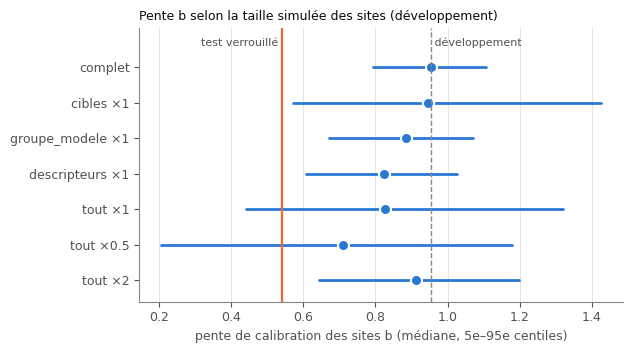

Écrit : ..\results\08_taille_sites\rapport_08.md | plan_08.json | replications_08.csv | signal_08.csv | gains_08.csv | figures/pente_taille.png


In [7]:
# ============================================================
# ÉTAPE 6 — FIGURE, CONTRÔLES, RAPPORT
# ============================================================
oc.check("Aucun hôpital verrouillé dans les tableaux analysés", not (set(ARR.H) & LOCKED), CONTROLES)
oc.check("Plan d'analyse inchangé pendant l'exécution", sha256(PLAN_PATH) == PLAN_SHA, CONTROLES)
CONTROLES_DF = pd.DataFrame(CONTROLES)
print(f"{int(CONTROLES_DF['ok'].sum())}/{len(CONTROLES_DF)} contrôles réussis")

import matplotlib.pyplot as plt
PAL = {"s1": "#2a78d6", "s2": "#eb6834", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": PAL["muted"],
                     "axes.labelcolor": PAL["ink2"], "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "font.size": 9})
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ys = np.arange(len(ORDER))[::-1]
for y, c in zip(ys, ORDER):
    b_ = b_of(c)
    ax.plot([b_.quantile(0.05), b_.quantile(0.95)], [y, y], color=PAL["s1"], lw=2, solid_capstyle="round")
    ax.plot(b_.median(), y, "o", ms=8, color=PAL["s1"], mec="white", mew=1.5)
ax.axvline(B_FULL, color=PAL["muted"], lw=1, ls="--")
ax.axvline(B_07, color=PAL["s2"], lw=1.6)
ax.text(B_FULL, ys[0] + 0.55, " développement", color=PAL["ink2"], fontsize=8, va="bottom")
ax.text(B_07, ys[0] + 0.55, "test verrouillé ", color=PAL["ink2"], fontsize=8, va="bottom", ha="right")
ax.set_yticks(ys); ax.set_yticklabels(ORDER)
ax.set_ylim(ys[-1] - 0.6, ys[0] + 1.1)
ax.set_xlabel("pente de calibration des sites b (médiane, 5e–95e centiles)")
ax.grid(axis="x", color=PAL["grid"], lw=0.6); ax.set_axisbelow(True)
ax.set_title("Pente b selon la taille simulée des sites (développement)", fontsize=9, color=PAL["ink"], loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "pente_taille.png", dpi=200); plt.show()

def md_table(df, digits=3):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    esc = lambda x: str(x).replace("|", "\\|")
    idx = df.index.names if isinstance(df.index, pd.MultiIndex) else [df.index.name or ""]
    head = "| " + " | ".join([esc(" / ".join(str(i) for i in idx))] + [esc(c) for c in df.columns]) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    lab = lambda i: " / ".join(map(str, i)) if isinstance(i, tuple) else i
    body = ["| " + " | ".join([esc(lab(i))] + [esc(v) for v in row]) + " |" for i, row in zip(df.index, df.to_numpy())]
    return "\n".join([head, sep] + body)

sig_cols = ["b", "b P5", "b P95", "part p_C1a ≤ 0,025", "lambda_eff", "var_ahat", "sejours_median", "part plafonnée"]
gain_cols = ["gain_E0", "gain_E0 P5", "gain_E0 P95", "part gain_E0 > 0", "|CITL| E0 − OP-Cal", "|CITL| E1 − OP-Cal", "gain_theorique", "part p_C1b ≤ 0,025"]
if HYP == "soutenue":
    phrase = ("La petite taille des hôpitaux verrouillés suffit à reproduire, sur le développement, la baisse de la pente observée au test verrouillé"
              + (" ; le mécanisme est l'erreur de mesure des descripteurs (le bruit des cibles seul ne l'explique pas)." if S3 else "."))
else:
    phrase = ("La petite taille des sites ne suffit pas à reproduire la baisse observée ; d'autres explications sont à examiner "
              "(domaine des hôpitaux verrouillés, modèle final, variabilité d'échantillonnage).")
rapport = f"""# Rapport 08 — taille des sites et pente de calibration (analyse exploratoire)

Généré le {datetime.now():%Y-%m-%d %H:%M} par `notebooks/08_taille_sites.ipynb`. Protocole `{protocol['hash']}`. Agrégats uniquement.
**Statut : exploratoire, après l'ouverture du test verrouillé.** Plan d'analyse `plan_08.json` du {PLAN['date']} (SHA-256 `{PLAN_SHA[:16]}…`) ; module `opcal_size.py` `{MOD_SHA[:16]}…`.
Hôpitaux de développement uniquement ; des hôpitaux verrouillés, seuls les effectifs du manifest, le b publié du 07 et les â_h gelés (sans label) sont lus.

Effectifs médians : verrouillés train {np.median(PAIRS[:, 0]):.0f}, évaluation {np.median(PAIRS[:, 1]):.0f} ; développement train {mdv['n_train'].median():.0f},
évaluation {(mdv['n_val'] + mdv['n_test']).median():.0f}. {N_DRAW} tirages × {len(FOLD_SETS)} jeux de plis (protocole + {N_PART} partitions du 06d).

## Pente b selon la taille

{md_table(TAB_SIG[sig_cols])}

## Hypothèse de taille : **{HYP}**

{md_table(VERDICT_H)}

b_complet = {B_FULL:.3f} ; b_tout = {B_TOUT:.3f} ; b_07 = {B_07:.3f} [{B_07_IC[0]:.3f} ; {B_07_IC[1]:.3f}].

**Lecture :** {phrase}

Dispersion des prédictions (sans label) :

{md_table(DISP, 4)}

## Signal et gain de calibration selon la taille

{md_table(TAB_GAIN[gain_cols], 4)}

## Correction de fiabilité : **{CORR}**

{md_table(TAB_CORR, 4) if TAB_CORR is not None else "Non évaluée."}

{md_table(VERDICT_K) if VERDICT_K is not None else ""}

Une correction retenue ici reste une **hypothèse** : elle n'est pas évaluée sur les 96 hôpitaux verrouillés (déjà utilisés) et demande une validation sur une autre source.

## Contrôles

{md_table(CONTROLES_DF.set_index('controle'))}
"""
(RES_DIR / "rapport_08.md").write_text(rapport, encoding="utf-8")
TAB_SIG.to_csv(RES_DIR / "signal_08.csv"); TAB_GAIN.to_csv(RES_DIR / "gains_08.csv")
print(f"Écrit : {RES_DIR / 'rapport_08.md'} | plan_08.json | replications_08.csv | signal_08.csv | gains_08.csv | figures/pente_taille.png")